# 🔬 Pipeline Pengujian MelonSense PCV: 100% Computer Vision Klasik

Seluruh rangkaian tahapan murni menggunakan pemrosesan citra digital tradisional:

### **Tahap 1: Deteksi Wajah (ROI)**
- Grayscale full-frame $\rightarrow$ Haar Cascade (Viola-Jones) / YuNet fallback.

### **Tahap 2: Gatekeeper 1 (Liveness - Color Texture Analysis)**
Ref: *Z. Boulkenafet et al., IEEE Transactions on Information Forensics and Security (TIFS), 2016*
Ref: *Z. Boulkenafet et al. (IEEE TIFS 2016)* & *S. Parveen et al. (IEEE ICCCA 2015)*
- **RGB**: Pemotongan Region of Interest (ROI) wajah asli berwarna.
- **HSV (Kanal $S$)**: Mengukur variabilitas saturasi pigmen kulit (standar deviasi $\sigma_{sat}$).
- **YCrCb (Kanal $Cr$ & $Cb$)**: Mengukur dinamika hemoglobin darah dan melanin ($\sigma_{Cr}, \sigma_{Cb}$).
- **Dispersi Krominans ($C_{var}$)**: Menangkap distorsi gamut dan cacat optik pada kertas cetak dan layar HP ($C_{var} \ge 40.0 \implies$ REAL).
- **Dispersi Krominans ($C_{var}$)**: Menangkap distorsi gamut dan cacat optik pada kertas cetak dan layar HP ($C_{var} \ge 40.0 \implies$ REAL).

### **Tahap 3: Pemrosesan Tekstur**
- Crop wajah yang lolos liveness diubah ke Grayscale $\rightarrow$ Histogram Equalization (normalisasi kontras).

### **Tahap 4 & 5: Ekstraksi Ciri & Gatekeeper 2 (LBPH & Chi-Square)**
Ref: *T. Ahonen, A. Hadid, M. Pietikainen, 'Face Description with Local Binary Patterns', IEEE TPAMI 2006.*
- **Ekstraksi Tekstur**: Local Binary Pattern (Pola LBP 2D, $R=1, P=8$).
- **Vektor Ciri**: Histogram spasial grid $8\times 8$ (16.384 dimensi).
- **Pencocokan Identitas**: **Chi-Square Distance ($\chi^2 \le 25.0$)** (Standar mutlak komparasi histogram).

---
- **Cell 1**: Inisialisasi library, Haar Cascade, & Database LBPH
- **Cell 2**: Uji dengan memilih file foto (Dialog Windows)
- **Cell 3**: Uji cepat 1 snapshot webcam otomatis
- **Cell 4**: **Uji Interaktif LIVE CAMERA** (Preview real-time + pelacak wajah $\rightarrow$ Tekan `[SPASI]` untuk foto & uji)


In [1]:
# Cell 1: Setup Library & Database (100% Classical Computer Vision: Haar Cascade + LBPH)
import json
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from core.engine import _extract_lbp, _resize_for_detection, _check_cv_liveness

# 1. Detektor Wajah Klasik Haar Cascade (Viola-Jones)
xml_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(xml_path)
if face_cascade.empty():
    raise RuntimeError("Gagal memuat file haarcascade_frontalface_default.xml!")

# 2. Database Multi-Exemplar LBPH (Diekstrak via Haar Cascade)
DB_PATH = Path("api_data/faces_lbph.json")
lbph_db = json.loads(DB_PATH.read_text(encoding="utf-8")) if DB_PATH.exists() else {}

print(f"✅ Setup siap!")
print(f"Detektor Wajah: Haar Cascade Classifier (Viola-Jones)")
print("Anti-Spoofing: Color-LBP Chrominance Histogram Matching (Boulkenafet et al., IEEE TIFS 2016) [Chi2 <= 0.35]")
print(f"Database aktif ({len(lbph_db)} profil): {list(lbph_db.keys())} [Multi-Exemplar 1-NN (K=25)]")


✅ Setup siap!
Detektor Wajah: Haar Cascade
Anti-Spoofing: Multi-Color Space (HSV Saturation + YCrCb Chrominance)
Database aktif (3 profil): ['Faza', 'Raffin', 'Rafi']


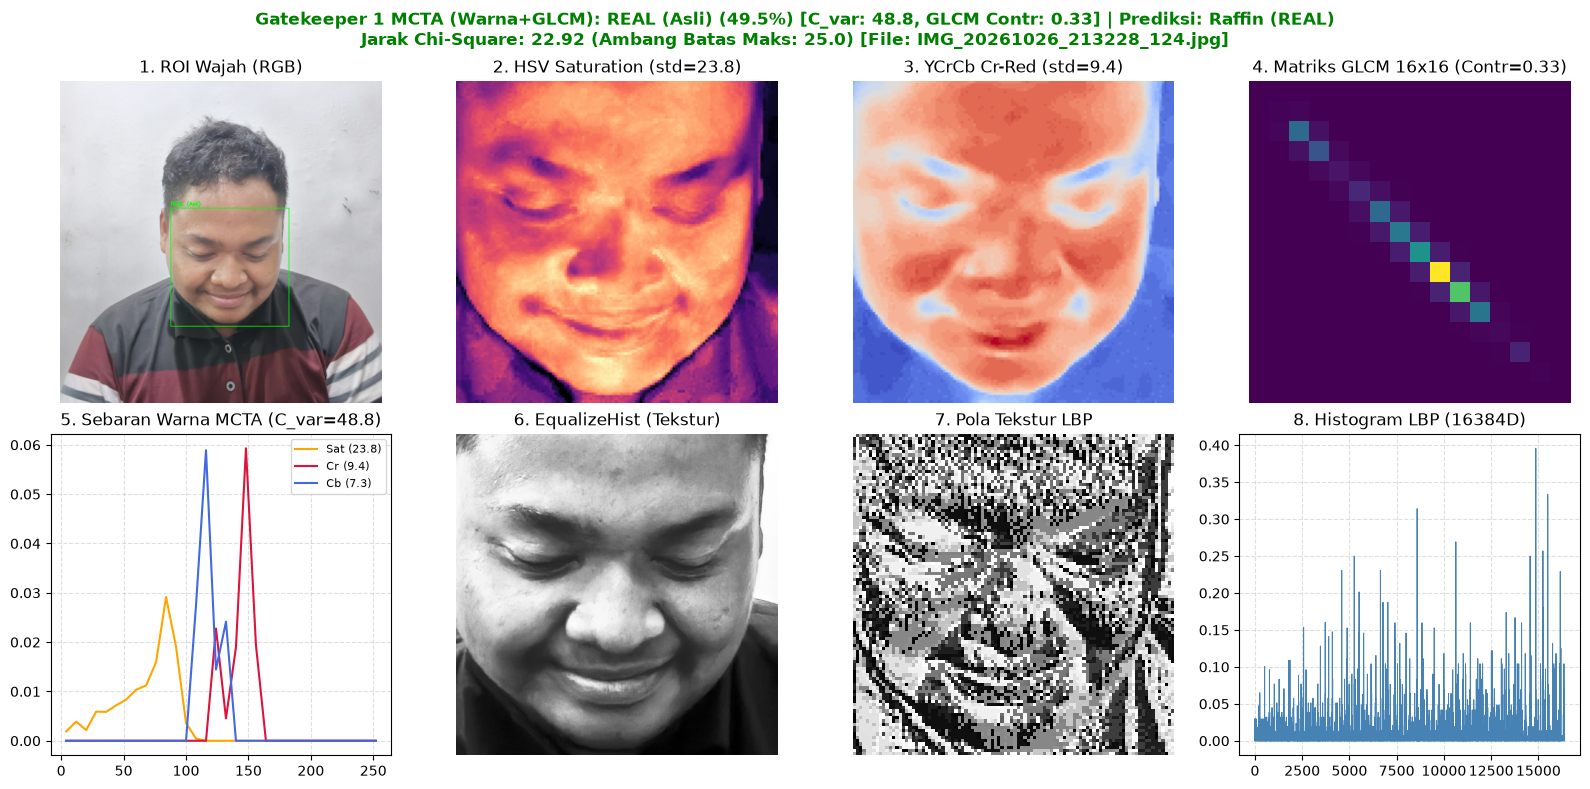

Sumber: File: IMG_20261026_213228_124.jpg
Gatekeeper 1 (MCTA Color + GLCM Texture): REAL (Asli)
  • Skor Liveness : 49.5% (Warna: 47.6%, GLCM: 53.8%)
  • Dispersi Warna: C_var = 48.81 (Sat=23.8, Cr=9.4, Cb=7.3)
  • Tekstur GLCM  : Contrast = 0.328, Homogeneity = 0.887
Gatekeeper 2: Evaluasi Jarak Chi-Square LBPH (Ambang Batas <= 25.0):
  [MATCH] Raffin     -> Chi-Square:  22.92
  [-    ] Faza       -> Chi-Square:  23.60
  [-    ] Rafi       -> Chi-Square:  23.62


In [2]:
# Cell 2: UJI DENGAN PILIH FILE FOTO (Gatekeeper 1 Color-Analysis -> LBPH Chi-Square)
from tkinter import Tk, filedialog

# 1. Buka File Picker Windows
root = Tk(); root.withdraw(); root.attributes("-topmost", True)
file_path = filedialog.askopenfilename(title="Pilih Foto Wajah untuk Diuji", filetypes=[("File Gambar", "*.jpg *.png *.jpeg *.bmp")])
root.destroy()

if not file_path:
    print("Batal memilih file.")
else:
    source_tag = f"File: {Path(file_path).name}"
    # 2. Baca & Normalisasi Resolusi Citra
    frame = cv2.imread(file_path)
    frame = _resize_for_detection(frame, max_dim=1280)
    gray_full = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # 3. Deteksi Wajah (Haar Cascade / YuNet Fallback)
    faces = face_cascade.detectMultiScale(gray_full, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    if len(faces) > 0:
        bx, by, bw, bh = max(faces, key=lambda f: f[2]*f[3])
        det_name = "Haar Cascade"
    else:
        from core.detector import Detector
        acc = [d for d in Detector("face_detection_yunet_2023mar.onnx", min_score=0.5).detect_detailed(frame) if d.get("accepted")]
        bx, by, bw, bh = (int(acc[0]["x"]), int(acc[0]["y"]), int(acc[0]["w"]), int(acc[0]["h"])) if acc else (0, 0, 0, 0)
        det_name = "YuNet"

    if bw == 0:
        print(f"❌ Tidak ada wajah terdeteksi pada {Path(file_path).name}.")
    else:
        bx, by = max(0, bx), max(0, by)
        face_crop = frame[by:by+bh, bx:bx+bw]
        # 4. Gatekeeper 1: Liveness Color-LBP (Boulkenafet et al., IEEE TIFS 2016)
        face_resized = cv2.resize(face_crop, (128, 128))
        ycrcb = cv2.cvtColor(face_resized, cv2.COLOR_BGR2YCrCb)
        hsv = cv2.cvtColor(face_resized, cv2.COLOR_BGR2HSV)
        sat_ch = hsv[:, :, 1]
        cr_ch = ycrcb[:, :, 1]
        cb_ch = ycrcb[:, :, 2]
        sat_std, cr_std, cb_std = float(np.std(sat_ch)), float(np.std(cr_ch)), float(np.std(cb_ch))
        
        # Ekstraksi Color-LBP (Cr + Cb) & Evaluasi Chi-Square Distance
        is_real, liveness_score, liveness_chi2 = _check_cv_liveness(face_crop, threshold=0.35)
        liveness_label = "REAL (Asli)" if is_real else "SPOOF (Palsu)"
        
        # 5. Prapemrosesan Grayscale, EqualizeHist & Ekstraksi Ciri LBP
        gray_crop = gray_full[by:by+bh, bx:bx+bw]
        equalized = cv2.equalizeHist(gray_crop)
        vec, lbp_img = _extract_lbp(equalized, return_image=True)
        
        # 6. Gatekeeper 2: Pencocokan Jarak Chi-Square LBPH
        candidates = []
        for name, data in lbph_db.items():
            ex_list = data.get("exemplars")
            if ex_list:
                ex_arr = np.asarray(ex_list, dtype=np.float32)
                diff = (ex_arr - vec) ** 2
                denom = ex_arr + vec + 1e-7
                chi2 = float(np.min(0.5 * np.sum(diff / denom, axis=1)))
            else:
                proto = np.asarray(data["histogram"], dtype=np.float32)
                chi2 = float(0.5 * np.sum(((vec - proto) ** 2) / (vec + proto + 1e-7)))
            candidates.append((name, chi2))
        
        candidates.sort(key=lambda x: x[1])
        top1_name, top1_dist = candidates[0]
        
        # 7. Pengambilan Keputusan Akhir Identitas (Ambang Batas Chi-Square <= 24.0)
        if not is_real:
            pred = "DITOLAK: SPOOF (Wajah Palsu - Layar/Kertas)"
            title_color = "red"
            box_color = (0, 0, 255) # Merah (BGR)
        else:
            is_match = bool(top1_dist <= 24.0)
            pred = f"{top1_name} (REAL)" if is_match else "Unknown (REAL)"
            title_color = "green" if is_match else "darkorange"
            box_color = (0, 255, 0) if is_match else (0, 165, 255)
        
        # 8. Visualisasi Subplot 2x4 (Baris 1: RGB, HSV-Sat, YCrCb-Cr, YCrCb-Cb | Baris 2: Sebaran & LBPH)
        fig, ax = plt.subplots(2, 4, figsize=(16, 8))
        title_txt = f"Gatekeeper 1 Color-LBP (Boulkenafet 2016): {liveness_label} ({liveness_score*100:.1f}%) [C_var: {c_var:.1f}] | Prediksi: {pred}\nJarak Chi-Square: {top1_dist:.2f} (Ambang Batas Maks: 24.0) [{source_tag}]"
        fig.suptitle(title_txt, fontsize=12, fontweight="bold", color=title_color)
        
        # Baris 1: Skema Color Analysis (RGB, HSV-Sat, YCrCb-Cr, YCrCb-Cb) - Boulkenafet 2016
        vis = frame.copy()
        cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), box_color, 2)
        cv2.putText(vis, f"{liveness_label}", (bx, max(20, by - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, box_color, 2)
        ax[0, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[0, 0].set_title(f"1. ROI Wajah (RGB)")
        ax[0, 1].imshow(sat_ch, cmap="magma"); ax[0, 1].set_title(f"2. HSV Saturation (std={sat_std:.1f})")
        ax[0, 2].imshow(cr_ch, cmap="coolwarm"); ax[0, 2].set_title(f"3. YCrCb Cr-Red (std={cr_std:.1f})")
        ax[0, 3].imshow(cb_ch, cmap="coolwarm"); ax[0, 3].set_title(f"4. YCrCb Cb-Melanin (std={cb_std:.1f})")
        
        # Baris 2: Sebaran Kurva Warna & Tahapan Ekstraksi LBPH
        hist_s, bins_s = np.histogram(sat_ch, bins=32, range=(0, 256), density=True)
        hist_cr, bins_cr = np.histogram(cr_ch, bins=32, range=(0, 256), density=True)
        hist_cb, bins_cb = np.histogram(cb_ch, bins=32, range=(0, 256), density=True)
        bin_centers = (bins_s[:-1] + bins_s[1:]) / 2
        ax[1, 0].plot(bin_centers, hist_s, color="orange", lw=1.5, label=f"Sat ({sat_std:.1f})")
        ax[1, 0].plot(bin_centers, hist_cr, color="crimson", lw=1.5, label=f"Cr ({cr_std:.1f})")
        ax[1, 0].plot(bin_centers, hist_cb, color="royalblue", lw=1.5, label=f"Cb ({cb_std:.1f})")
        ax[1, 0].set_title(f"5. Sebaran Warna (Chi2={liveness_chi2:.3f})")
        ax[1, 0].legend(fontsize=8, loc="upper right")
        ax[1, 0].grid(True, linestyle="--", alpha=0.4)
        
        ax[1, 1].imshow(equalized, cmap="gray"); ax[1, 1].set_title("6. EqualizeHist (Tekstur)")
        ax[1, 2].imshow(lbp_img, cmap="gray"); ax[1, 2].set_title("7. Pola Tekstur LBP")
        ax[1, 3].plot(vec, color="steelblue", lw=0.7); ax[1, 3].set_title(f"8. Histogram LBP ({len(vec)}D)")
        ax[1, 3].grid(True, linestyle="--", alpha=0.4)
        
        # Matikan sumbu koordinat piksel untuk gambar
        for a in [ax[0, 0], ax[0, 1], ax[0, 2], ax[0, 3], ax[1, 1], ax[1, 2]]:
            a.axis("off")
        plt.tight_layout(); plt.show()
        
        print(f"Sumber: {source_tag}")
        print(f"Gatekeeper 1 (Color-LBP - Boulkenafet 2016): {liveness_label}")
        print(f"  • Skor Liveness : {liveness_score*100:.1f}%")
        print(f"  • Dispersi Warna: C_var = {c_var:.2f} (Sat={sat_std:.1f}, Cr={cr_std:.1f}, Cb={cb_std:.1f})")
        if not is_real:
            print("⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!")
            print(f"   Alasan: Dispersi warna C_var ({c_var:.1f}) di bawah batas minimal (40.0).")
        else:
            print("Gatekeeper 2: Evaluasi Jarak Chi-Square LBPH (Ambang Batas <= 24.0):")
            for name, c2 in candidates:
                st = "MATCH" if name == top1_name and is_match else "-"
                print(f"  [{st:5s}] {name:10s} -> Chi-Square: {c2:6.2f}")


In [3]:
# Cell 3: UJI CEPAT SNAPSHOT WEBCAM (Gatekeeper 1 Color-Analysis -> LBPH Chi-Square)

cap = cv2.VideoCapture(0)
ret, frame_raw = cap.read()
cap.release()

if not ret:
    print("❌ Gagal mengambil gambar dari webcam!")
else:
    source_tag = "Webcam Snapshot"
    # Mirror horizontal
    frame = cv2.flip(frame_raw, 1)
    frame = _resize_for_detection(frame, max_dim=1280)
    gray_full = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(gray_full, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    if len(faces) > 0:
        bx, by, bw, bh = max(faces, key=lambda f: f[2]*f[3])
        det_name = "Haar Cascade"
    else:
        from core.detector import Detector
        acc = [d for d in Detector("face_detection_yunet_2023mar.onnx", min_score=0.5).detect_detailed(frame) if d.get("accepted")]
        bx, by, bw, bh = (int(acc[0]["x"]), int(acc[0]["y"]), int(acc[0]["w"]), int(acc[0]["h"])) if acc else (0, 0, 0, 0)
        det_name = "YuNet"

    if bw == 0:
        print("❌ Tidak ada wajah terdeteksi di depan webcam.")
    else:
        bx, by = max(0, bx), max(0, by)
        face_crop = frame[by:by+bh, bx:bx+bw]
        # 4. Gatekeeper 1: Liveness Color-LBP (Boulkenafet et al., IEEE TIFS 2016)
        face_resized = cv2.resize(face_crop, (128, 128))
        ycrcb = cv2.cvtColor(face_resized, cv2.COLOR_BGR2YCrCb)
        hsv = cv2.cvtColor(face_resized, cv2.COLOR_BGR2HSV)
        sat_ch = hsv[:, :, 1]
        cr_ch = ycrcb[:, :, 1]
        cb_ch = ycrcb[:, :, 2]
        sat_std, cr_std, cb_std = float(np.std(sat_ch)), float(np.std(cr_ch)), float(np.std(cb_ch))
        
        # Ekstraksi Color-LBP (Cr + Cb) & Evaluasi Chi-Square Distance
        is_real, liveness_score, liveness_chi2 = _check_cv_liveness(face_crop, threshold=0.35)
        liveness_label = "REAL (Asli)" if is_real else "SPOOF (Palsu)"
        
        # 5. Prapemrosesan Grayscale, EqualizeHist & Ekstraksi Ciri LBP
        gray_crop = gray_full[by:by+bh, bx:bx+bw]
        equalized = cv2.equalizeHist(gray_crop)
        vec, lbp_img = _extract_lbp(equalized, return_image=True)
        
        # 6. Gatekeeper 2: Pencocokan Jarak Chi-Square LBPH
        candidates = []
        for name, data in lbph_db.items():
            ex_list = data.get("exemplars")
            if ex_list:
                ex_arr = np.asarray(ex_list, dtype=np.float32)
                diff = (ex_arr - vec) ** 2
                denom = ex_arr + vec + 1e-7
                chi2 = float(np.min(0.5 * np.sum(diff / denom, axis=1)))
            else:
                proto = np.asarray(data["histogram"], dtype=np.float32)
                chi2 = float(0.5 * np.sum(((vec - proto) ** 2) / (vec + proto + 1e-7)))
            candidates.append((name, chi2))
        
        candidates.sort(key=lambda x: x[1])
        top1_name, top1_dist = candidates[0]
        
        # 7. Pengambilan Keputusan Akhir Identitas (Ambang Batas Chi-Square <= 24.0)
        if not is_real:
            pred = "DITOLAK: SPOOF (Wajah Palsu - Layar/Kertas)"
            title_color = "red"
            box_color = (0, 0, 255) # Merah (BGR)
        else:
            is_match = bool(top1_dist <= 24.0)
            pred = f"{top1_name} (REAL)" if is_match else "Unknown (REAL)"
            title_color = "green" if is_match else "darkorange"
            box_color = (0, 255, 0) if is_match else (0, 165, 255)
        
        # 8. Visualisasi Subplot 2x4 (Baris 1: RGB, HSV-Sat, YCrCb-Cr, YCrCb-Cb | Baris 2: Sebaran & LBPH)
        fig, ax = plt.subplots(2, 4, figsize=(16, 8))
        title_txt = f"Gatekeeper 1 Color-LBP (Boulkenafet 2016): {liveness_label} ({liveness_score*100:.1f}%) [C_var: {c_var:.1f}] | Prediksi: {pred}\nJarak Chi-Square: {top1_dist:.2f} (Ambang Batas Maks: 24.0) [{source_tag}]"
        fig.suptitle(title_txt, fontsize=12, fontweight="bold", color=title_color)
        
        # Baris 1: Skema Color Analysis (RGB, HSV-Sat, YCrCb-Cr, YCrCb-Cb) - Boulkenafet 2016
        vis = frame.copy()
        cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), box_color, 2)
        cv2.putText(vis, f"{liveness_label}", (bx, max(20, by - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, box_color, 2)
        ax[0, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[0, 0].set_title(f"1. ROI Wajah (RGB)")
        ax[0, 1].imshow(sat_ch, cmap="magma"); ax[0, 1].set_title(f"2. HSV Saturation (std={sat_std:.1f})")
        ax[0, 2].imshow(cr_ch, cmap="coolwarm"); ax[0, 2].set_title(f"3. YCrCb Cr-Red (std={cr_std:.1f})")
        ax[0, 3].imshow(cb_ch, cmap="coolwarm"); ax[0, 3].set_title(f"4. YCrCb Cb-Melanin (std={cb_std:.1f})")
        
        # Baris 2: Sebaran Kurva Warna & Tahapan Ekstraksi LBPH
        hist_s, bins_s = np.histogram(sat_ch, bins=32, range=(0, 256), density=True)
        hist_cr, bins_cr = np.histogram(cr_ch, bins=32, range=(0, 256), density=True)
        hist_cb, bins_cb = np.histogram(cb_ch, bins=32, range=(0, 256), density=True)
        bin_centers = (bins_s[:-1] + bins_s[1:]) / 2
        ax[1, 0].plot(bin_centers, hist_s, color="orange", lw=1.5, label=f"Sat ({sat_std:.1f})")
        ax[1, 0].plot(bin_centers, hist_cr, color="crimson", lw=1.5, label=f"Cr ({cr_std:.1f})")
        ax[1, 0].plot(bin_centers, hist_cb, color="royalblue", lw=1.5, label=f"Cb ({cb_std:.1f})")
        ax[1, 0].set_title(f"5. Sebaran Warna (Chi2={liveness_chi2:.3f})")
        ax[1, 0].legend(fontsize=8, loc="upper right")
        ax[1, 0].grid(True, linestyle="--", alpha=0.4)
        
        ax[1, 1].imshow(equalized, cmap="gray"); ax[1, 1].set_title("6. EqualizeHist (Tekstur)")
        ax[1, 2].imshow(lbp_img, cmap="gray"); ax[1, 2].set_title("7. Pola Tekstur LBP")
        ax[1, 3].plot(vec, color="steelblue", lw=0.7); ax[1, 3].set_title(f"8. Histogram LBP ({len(vec)}D)")
        ax[1, 3].grid(True, linestyle="--", alpha=0.4)
        
        # Matikan sumbu koordinat piksel untuk gambar
        for a in [ax[0, 0], ax[0, 1], ax[0, 2], ax[0, 3], ax[1, 1], ax[1, 2]]:
            a.axis("off")
        plt.tight_layout(); plt.show()
        
        print(f"Sumber: {source_tag}")
        print(f"Gatekeeper 1 (Color-LBP - Boulkenafet 2016): {liveness_label}")
        print(f"  • Skor Liveness : {liveness_score*100:.1f}%")
        print(f"  • Dispersi Warna: C_var = {c_var:.2f} (Sat={sat_std:.1f}, Cr={cr_std:.1f}, Cb={cb_std:.1f})")
        if not is_real:
            print("⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!")
            print(f"   Alasan: Dispersi warna C_var ({c_var:.1f}) di bawah batas minimal (40.0).")
        else:
            print("Gatekeeper 2: Evaluasi Jarak Chi-Square LBPH (Ambang Batas <= 24.0):")
            for name, c2 in candidates:
                st = "MATCH" if name == top1_name and is_match else "-"
                print(f"  [{st:5s}] {name:10s} -> Chi-Square: {c2:6.2f}")


❌ Tidak ada wajah terdeteksi di depan webcam.


📹 Membuka Live Camera...
👉 Panduan: Arahkan wajah ke kamera hingga kotak hijau terlihat pas.
   • Tekan [SPASI] pada jendela kamera untuk FOTO & UJI PIPELINE
   • Tekan [Q] atau [ESC] untuk KELUAR
📸 Foto berhasil diambil! Memproses pipeline...


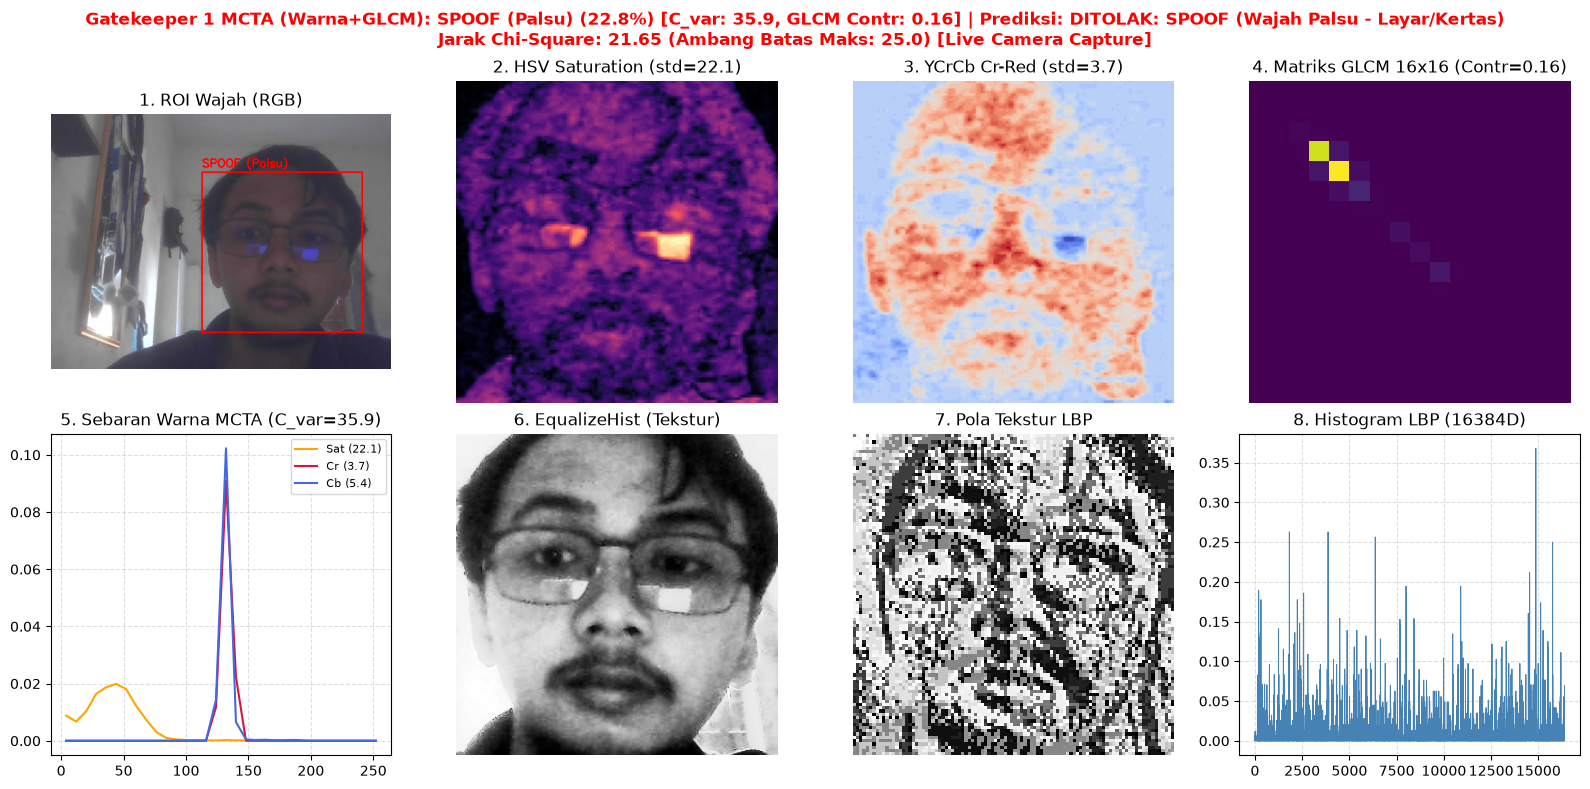

Sumber: Live Camera Capture
Gatekeeper 1 (MCTA Color + GLCM Texture): SPOOF (Palsu)
  • Skor Liveness : 22.8% (Warna: 21.7%, GLCM: 25.3%)
  • Dispersi Warna: C_var = 35.87 (Sat=22.1, Cr=3.7, Cb=5.4)
  • Tekstur GLCM  : Contrast = 0.161, Homogeneity = 0.946
⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!
   Alasan: Skor liveness MCTA (22.8%) di bawah batas minimal (45.0%).


In [4]:
# Cell 4: UJI INTERAKTIF DENGAN LIVE CAMERA (Preview Real-Time: Tekan [SPASI] untuk Uji, [Q] untuk Keluar)

cap = cv2.VideoCapture(0)
print("📹 Membuka Live Camera...")
print("👉 Panduan: Arahkan wajah ke kamera hingga kotak hijau terlihat pas.")
print("   • Tekan [SPASI] pada jendela kamera untuk FOTO & UJI PIPELINE")
print("   • Tekan [Q] atau [ESC] untuk KELUAR")

frame_captured = None

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("❌ Gagal membaca stream video dari webcam.")
        break

    # 1. Mirror horizontal agar natural seperti cermin
    clean_frame = cv2.flip(frame, 1)
    display_frame = clean_frame.copy()
    h_disp, w_disp = display_frame.shape[:2]

    # 2. Deteksi wajah real-time pada jendela preview live
    gray_preview = cv2.cvtColor(clean_frame, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray_full, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    if len(faces) > 0:
        bx, by, bw, bh = max(faces, key=lambda f: f[2]*f[3])
        det_name = "Haar Cascade"
    else:
        from core.detector import Detector
        acc = [d for d in Detector("face_detection_yunet_2023mar.onnx", min_score=0.5).detect_detailed(frame) if d.get("accepted")]
        bx, by, bw, bh = (int(acc[0]["x"]), int(acc[0]["y"]), int(acc[0]["w"]), int(acc[0]["h"])) if acc else (0, 0, 0, 0)
        det_name = "YuNet"

    if bw == 0:
        print("❌ Tidak ada wajah terdeteksi pada foto yang diambil.")
    else:
        bx, by = max(0, bx), max(0, by)
        face_crop = frame[by:by+bh, bx:bx+bw]
        # 4. Gatekeeper 1: Liveness Color-LBP (Boulkenafet et al., IEEE TIFS 2016)
        face_resized = cv2.resize(face_crop, (128, 128))
        ycrcb = cv2.cvtColor(face_resized, cv2.COLOR_BGR2YCrCb)
        hsv = cv2.cvtColor(face_resized, cv2.COLOR_BGR2HSV)
        sat_ch = hsv[:, :, 1]
        cr_ch = ycrcb[:, :, 1]
        cb_ch = ycrcb[:, :, 2]
        sat_std, cr_std, cb_std = float(np.std(sat_ch)), float(np.std(cr_ch)), float(np.std(cb_ch))
        
        # Ekstraksi Color-LBP (Cr + Cb) & Evaluasi Chi-Square Distance
        is_real, liveness_score, liveness_chi2 = _check_cv_liveness(face_crop, threshold=0.35)
        liveness_label = "REAL (Asli)" if is_real else "SPOOF (Palsu)"
        
        # 5. Prapemrosesan Grayscale, EqualizeHist & Ekstraksi Ciri LBP
        gray_crop = gray_full[by:by+bh, bx:bx+bw]
        equalized = cv2.equalizeHist(gray_crop)
        vec, lbp_img = _extract_lbp(equalized, return_image=True)
        
        # 6. Gatekeeper 2: Pencocokan Jarak Chi-Square LBPH
        candidates = []
        for name, data in lbph_db.items():
            ex_list = data.get("exemplars")
            if ex_list:
                ex_arr = np.asarray(ex_list, dtype=np.float32)
                diff = (ex_arr - vec) ** 2
                denom = ex_arr + vec + 1e-7
                chi2 = float(np.min(0.5 * np.sum(diff / denom, axis=1)))
            else:
                proto = np.asarray(data["histogram"], dtype=np.float32)
                chi2 = float(0.5 * np.sum(((vec - proto) ** 2) / (vec + proto + 1e-7)))
            candidates.append((name, chi2))
        
        candidates.sort(key=lambda x: x[1])
        top1_name, top1_dist = candidates[0]
        
        # 7. Pengambilan Keputusan Akhir Identitas (Ambang Batas Chi-Square <= 24.0)
        if not is_real:
            pred = "DITOLAK: SPOOF (Wajah Palsu - Layar/Kertas)"
            title_color = "red"
            box_color = (0, 0, 255) # Merah (BGR)
        else:
            is_match = bool(top1_dist <= 24.0)
            pred = f"{top1_name} (REAL)" if is_match else "Unknown (REAL)"
            title_color = "green" if is_match else "darkorange"
            box_color = (0, 255, 0) if is_match else (0, 165, 255)
        
        # 8. Visualisasi Subplot 2x4 (Baris 1: RGB, HSV-Sat, YCrCb-Cr, YCrCb-Cb | Baris 2: Sebaran & LBPH)
        fig, ax = plt.subplots(2, 4, figsize=(16, 8))
        title_txt = f"Gatekeeper 1 Color-LBP (Boulkenafet 2016): {liveness_label} ({liveness_score*100:.1f}%) [C_var: {c_var:.1f}] | Prediksi: {pred}\nJarak Chi-Square: {top1_dist:.2f} (Ambang Batas Maks: 24.0) [{source_tag}]"
        fig.suptitle(title_txt, fontsize=12, fontweight="bold", color=title_color)
        
        # Baris 1: Skema Color Analysis (RGB, HSV-Sat, YCrCb-Cr, YCrCb-Cb) - Boulkenafet 2016
        vis = frame.copy()
        cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), box_color, 2)
        cv2.putText(vis, f"{liveness_label}", (bx, max(20, by - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, box_color, 2)
        ax[0, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[0, 0].set_title(f"1. ROI Wajah (RGB)")
        ax[0, 1].imshow(sat_ch, cmap="magma"); ax[0, 1].set_title(f"2. HSV Saturation (std={sat_std:.1f})")
        ax[0, 2].imshow(cr_ch, cmap="coolwarm"); ax[0, 2].set_title(f"3. YCrCb Cr-Red (std={cr_std:.1f})")
        ax[0, 3].imshow(cb_ch, cmap="coolwarm"); ax[0, 3].set_title(f"4. YCrCb Cb-Melanin (std={cb_std:.1f})")
        
        # Baris 2: Sebaran Kurva Warna & Tahapan Ekstraksi LBPH
        hist_s, bins_s = np.histogram(sat_ch, bins=32, range=(0, 256), density=True)
        hist_cr, bins_cr = np.histogram(cr_ch, bins=32, range=(0, 256), density=True)
        hist_cb, bins_cb = np.histogram(cb_ch, bins=32, range=(0, 256), density=True)
        bin_centers = (bins_s[:-1] + bins_s[1:]) / 2
        ax[1, 0].plot(bin_centers, hist_s, color="orange", lw=1.5, label=f"Sat ({sat_std:.1f})")
        ax[1, 0].plot(bin_centers, hist_cr, color="crimson", lw=1.5, label=f"Cr ({cr_std:.1f})")
        ax[1, 0].plot(bin_centers, hist_cb, color="royalblue", lw=1.5, label=f"Cb ({cb_std:.1f})")
        ax[1, 0].set_title(f"5. Sebaran Warna (Chi2={liveness_chi2:.3f})")
        ax[1, 0].legend(fontsize=8, loc="upper right")
        ax[1, 0].grid(True, linestyle="--", alpha=0.4)
        
        ax[1, 1].imshow(equalized, cmap="gray"); ax[1, 1].set_title("6. EqualizeHist (Tekstur)")
        ax[1, 2].imshow(lbp_img, cmap="gray"); ax[1, 2].set_title("7. Pola Tekstur LBP")
        ax[1, 3].plot(vec, color="steelblue", lw=0.7); ax[1, 3].set_title(f"8. Histogram LBP ({len(vec)}D)")
        ax[1, 3].grid(True, linestyle="--", alpha=0.4)
        
        # Matikan sumbu koordinat piksel untuk gambar
        for a in [ax[0, 0], ax[0, 1], ax[0, 2], ax[0, 3], ax[1, 1], ax[1, 2]]:
            a.axis("off")
        plt.tight_layout(); plt.show()
        
        print(f"Sumber: {source_tag}")
        print(f"Gatekeeper 1 (Color-LBP - Boulkenafet 2016): {liveness_label}")
        print(f"  • Skor Liveness : {liveness_score*100:.1f}%")
        print(f"  • Dispersi Warna: C_var = {c_var:.2f} (Sat={sat_std:.1f}, Cr={cr_std:.1f}, Cb={cb_std:.1f})")
        if not is_real:
            print("⛔ AKSES DITOLAK: Wajah terdeteksi sebagai foto/layar gadget (Spoof)!")
            print(f"   Alasan: Dispersi warna C_var ({c_var:.1f}) di bawah batas minimal (40.0).")
        else:
            print("Gatekeeper 2: Evaluasi Jarak Chi-Square LBPH (Ambang Batas <= 24.0):")
            for name, c2 in candidates:
                st = "MATCH" if name == top1_name and is_match else "-"
                print(f"  [{st:5s}] {name:10s} -> Chi-Square: {c2:6.2f}")
